# KG Water Intelligence — Day 6: Defining a water-stress target

**Goal:** decide how the project will *measure* agricultural water stress before any model is trained.

**Candidate target:** the **soil-moisture anomaly** — how far ERA5-Land soil moisture is from its normal value *for the same place and time of year*. It is an **indicator**, not proof that a field needs irrigation.

**Rule from the plan:** a field is *not* called "water-stressed" just because its NDVI is low (crop type, harvest, disease and the season all lower NDVI). NDVI is used here only as an independent consistency check.

Written definition: [`docs/water_stress_target.md`](../docs/water_stress_target.md).

In [1]:
import numpy as np, pandas as pd, xarray as xr, glob, warnings
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.stats import spearmanr, rankdata
warnings.filterwarnings("ignore"); pd.set_option("display.width", 150)
FIG = "../reports/figures/"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SOIL, RAIN, TEMP, NDVI, FLAG = "#8a5a2b", "#2a78d6", "#eb6834", "#2e8b57", "#e5483c"
def style(ax, ygrid=True):
    ax.set_facecolor(SURF); [ax.spines[s].set_visible(False) for s in ("top", "right", "left")]; ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=10)
    if ygrid: ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
d = pd.read_csv("../data/processed/sokuluk_grid_daily.csv.gz", parse_dates=["date"]).sort_values(["cell_id", "date"]).reset_index(drop=True)
YEARS = sorted(d.date.dt.year.unique()); print(f"{len(d):,} rows, {d.cell_id.nunique()} cells, years {YEARS[0]}-{YEARS[-1]}")

76,680 rows, 30 cells, years 2018-2024


## 1. Which soil-moisture data do we have?

In [2]:
ds = xr.open_dataset(sorted(glob.glob("../data/raw/era5land/era5land_*.nc"))[-1])
for v in ("swvl1", "swvl2"): print(f"{v}: {ds[v].attrs.get('long_name')}  | units: {ds[v].attrs.get('units')}")
sm = d[["soil_moisture_l1_m3m3", "soil_moisture_l2_m3m3"]]
pd.DataFrame({"layer": ["0–7 cm", "7–28 cm"], "min": sm.min().round(3).values, "median": sm.median().round(3).values, "max": sm.max().round(3).values, "missing": sm.isna().sum().values,
              "days × cells": [len(d)] * 2}, index=["soil_moisture_l1_m3m3", "soil_moisture_l2_m3m3"])

swvl1: Volumetric soil water layer 1  | units: m**3 m**-3
swvl2: Volumetric soil water layer 2  | units: m**3 m**-3


,layer,min,median,max,missing,days × cells
soil_moisture_l1_m3m3,0–7 cm,0.121,0.351,0.506,0,76680
soil_moisture_l2_m3m3,7–28 cm,0.145,0.345,0.498,0,76680


**What is available:** ERA5-Land volumetric soil water (m³ of water per m³ of soil) for the top two layers, every day and every cell, 2018–2024, no gaps, physically plausible range.
**What is missing:** layers 3 (28–100 cm) and 4 (100–289 cm) were not downloaded; the **28–100 cm layer is closer to a crop's root zone** and should be added (a CDS request, queue time only). Soil moisture is a *model* product at ~9 km, not a field measurement.

## 2. Seasonal patterns

In [3]:
w = lambda g, c: np.average(g[c], weights=g.cropland_km2)
dist = d.groupby("date").apply(lambda g: pd.Series({"sm1": w(g, "soil_moisture_l1_m3m3"), "sm2": w(g, "soil_moisture_l2_m3m3"), "rain": w(g, "precipitation_mm"), "t": w(g, "temperature_2m_c")}))
dist["y"] = dist.index.year; dist["m"] = dist.index.month; dist["doy"] = np.minimum(dist.index.dayofyear, 365)
mon = dist.groupby("m").agg(sm1=("sm1", "mean"), sm2=("sm2", "mean"), t=("t", "mean")); mon["rain_mm"] = dist.groupby(["y", "m"]).rain.sum().groupby("m").mean()
mon.round(3).T

m,1,2,3,4,5,6,7,8,9,10,11,12
sm1,0.369,0.387,0.405,0.384,0.324,0.238,0.206,0.208,0.226,0.291,0.354,0.366
sm2,0.355,0.375,0.402,0.385,0.328,0.246,0.212,0.204,0.214,0.254,0.323,0.349
t,-2.909,-0.418,5.994,12.151,17.218,22.432,25.723,23.597,18.117,10.445,2.366,-1.979
rain_mm,34.205,54.478,111.611,115.676,70.315,30.632,23.930,29.068,30.062,54.777,61.896,40.625


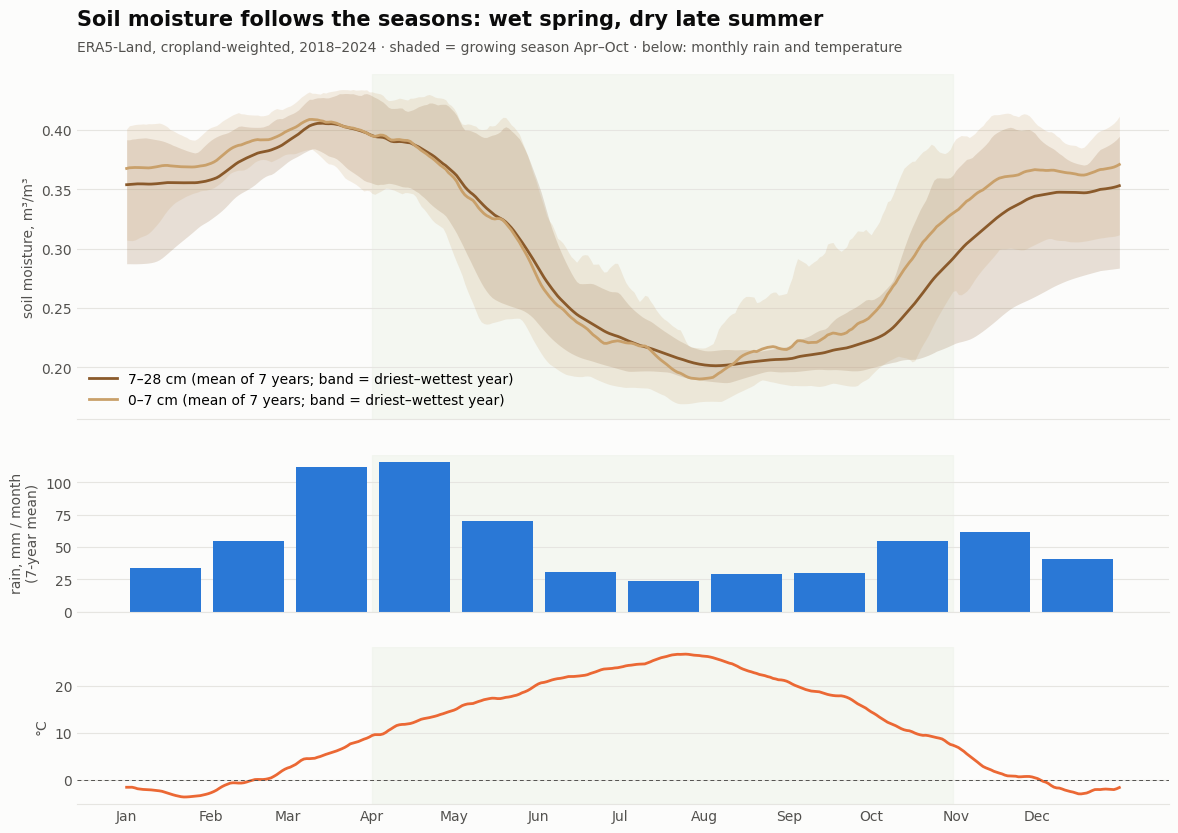

layer 2 (7-28 cm): March peak 0.402, July-Aug low 0.208 m3/m3


In [4]:
# Figure 1 - seasonal cycle: soil moisture (two layers, spread across years), rain, temperature
doy = dist.groupby("doy")
def smooth(s, k=15): return s.rolling(k, center=True, min_periods=1).mean()
fig, ax = plt.subplots(3, 1, figsize=(12, 8.8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]}); fig.subplots_adjust(left=.07, right=.98, top=.9, bottom=.07, hspace=.16); fig.set_facecolor(SURF)
x = np.arange(1, 366)
for col, c, lab in (("sm2", SOIL, "7–28 cm"), ("sm1", "#c9a06a", "0–7 cm")):
    yy = dist.pivot_table(index="doy", columns="y", values=col); ax[0].fill_between(x, smooth(yy.min(axis=1)).values, smooth(yy.max(axis=1)).values, color=c, alpha=.18, lw=0); ax[0].plot(x, smooth(yy.mean(axis=1)).values, color=c, lw=2, label=f"{lab} (mean of 7 years; band = driest–wettest year)")
ax[0].legend(frameon=False, fontsize=10, loc="lower left"); style(ax[0]); ax[0].set_ylabel("soil moisture, m³/m³", color=INK2)
rr = dist.groupby(["y", "m"]).rain.sum().groupby("m").mean(); ax[1].bar(rr.index * 30.4 - 15, rr.values, width=26, color=RAIN); style(ax[1]); ax[1].set_ylabel("rain, mm / month\n(7-year mean)", color=INK2)
tt = smooth(doy.t.mean()); ax[2].plot(x, tt.values, color=TEMP, lw=2); style(ax[2]); ax[2].axhline(0, color=INK2, lw=.7, ls=(0, (4, 3))); ax[2].set_ylabel("°C", color=INK2)
ax[2].set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]); ax[2].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
for a_ in ax: a_.axvspan(91, 304, color="#eef3ea", alpha=.55, zorder=0)
fig.text(.07, .955, "Soil moisture follows the seasons: wet spring, dry late summer", fontsize=15, fontweight="bold", color=INK)
fig.text(.07, .925, "ERA5-Land, cropland-weighted, 2018–2024 · shaded = growing season Apr–Oct · below: monthly rain and temperature", fontsize=10, color=INK2)
fig.savefig(FIG + "target_seasonal_cycle.png", dpi=170); plt.show()
print("layer 2 (7-28 cm): March peak %.3f, July-Aug low %.3f m3/m3" % (mon.sm2[3], mon.sm2[[7, 8]].mean()))

**Reading it:** soil is wettest in March–April (snowmelt and spring rain) and driest in July–August, when it is hot and dry; it recovers in autumn. So an *absolute* soil-moisture value is meaningless as a stress signal: July at 0.21 is normal, March at 0.21 would be extreme. That is exactly why the target must be an **anomaly against the same time of year**.

## 3. The anomaly: soil moisture vs its normal for that place and day

For each cell and day of year, *normal* = mean and standard deviation of that day ±15 days across the **other** years (leave-one-year-out, so a year is never compared with a baseline that contains itself). The anomaly is a z-score: **z = (value − normal) / standard deviation**. z ≤ −1 means "drier than usual for the date".

In [5]:
def loyo_z(cell_df, col, win=15):
    doy_ = np.minimum(cell_df.date.dt.dayofyear.values, 365); yr = cell_df.date.dt.year.values; M = np.full((len(YEARS), 365), np.nan)
    for i, y in enumerate(YEARS): m = yr == y; M[i, doy_[m] - 1] = cell_df[col].values[m]
    k = np.ones(2 * win + 1)
    circ = lambda A: np.apply_along_axis(lambda r: np.convolve(r, k, mode="valid"), 1, np.concatenate([A[:, -win:], A, A[:, :win]], axis=1))
    V = ~np.isnan(M); S, Q, Nn = circ(np.nan_to_num(M)), circ(np.nan_to_num(M) ** 2), circ(V.astype(float))
    mu = (S.sum(0) - S) / (Nn.sum(0) - Nn); sd = np.maximum(np.sqrt(np.maximum((Q.sum(0) - Q) / (Nn.sum(0) - Nn) - mu ** 2, 1e-6)), 0.01)
    yi = np.searchsorted(YEARS, yr); return (cell_df[col].values - mu[yi, doy_ - 1]) / sd[yi, doy_ - 1]
d["z_l2"] = np.nan; d["z_l1"] = np.nan
for c, g_ in d.groupby("cell_id"): d.loc[g_.index, "z_l2"] = loyo_z(g_, "soil_moisture_l2_m3m3"); d.loc[g_.index, "z_l1"] = loyo_z(g_, "soil_moisture_l1_m3m3")
d["m"] = d.date.dt.month; d["y"] = d.date.dt.year; d["flag"] = (d.z_l2 <= -1).astype(int)
dz = d.groupby("date").apply(lambda g: pd.Series({"z2": w(g, "z_l2"), "z1": w(g, "z_l1")})); dz["y"] = dz.index.year; dz["m"] = dz.index.month
dist = dist.join(dz[["z2", "z1"]]); print(f"anomaly computed for {d.z_l2.notna().sum():,} cell-days; overall mean {d.z_l2.mean():+.2f}, sd {d.z_l2.std():.2f}")
d[["date", "cell_id", "soil_moisture_l2_m3m3", "z_l2", "z_l1"]].round(3).to_csv("../data/processed/soil_moisture_anomaly_loyo.csv.gz", index=False, compression="gzip")

anomaly computed for 76,680 cell-days; overall mean -0.03, sd 1.09


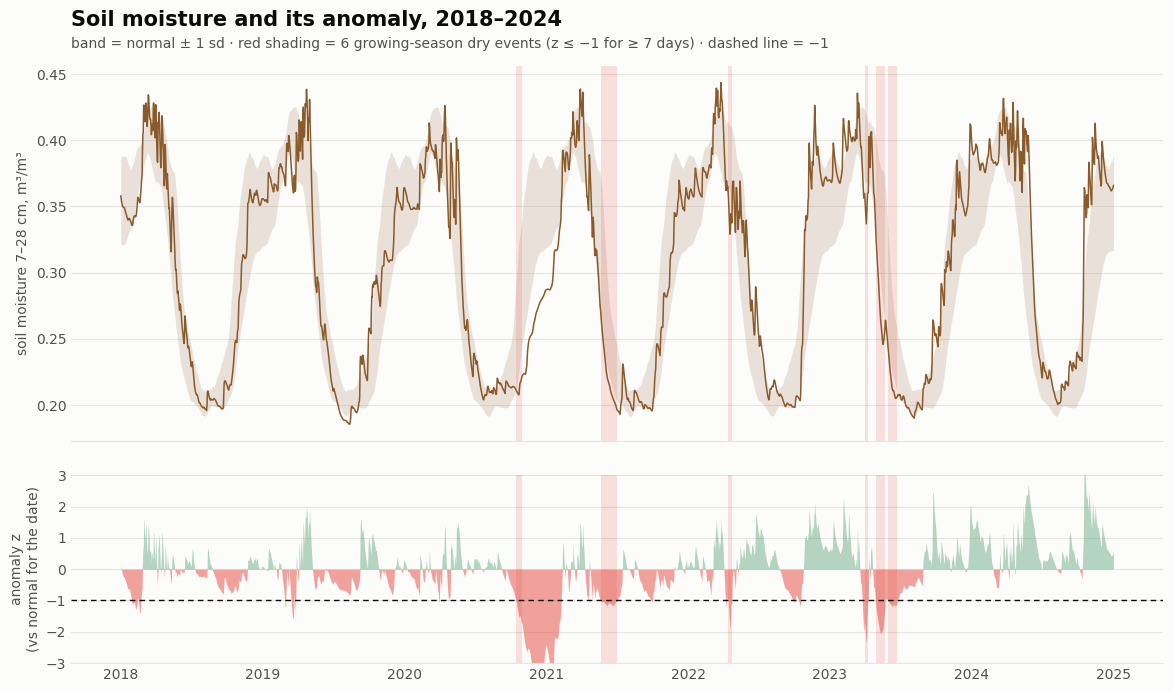

,start,end,days
0,2020-10-15,2020-10-31,17
1,2021-05-22,2021-07-02,42
2,2022-04-15,2022-04-24,10
3,2023-04-01,2023-04-10,10
4,2023-04-29,2023-05-23,25
5,2023-05-31,2023-06-24,25


In [6]:
# Figure 2 - soil moisture through time, with its normal band and the dry events
g = dist[dist.m.between(4, 10)]
def events(z, minlen=7):
    f = (z <= -1).values; ev, i = [], 0
    while i < len(f):
        if f[i]:
            j = i
            while j < len(f) and f[j]: j += 1
            if j - i >= minlen: ev.append((z.index[i], z.index[j - 1], j - i))
            i = j
        else: i += 1
    return ev
EV = [e for _, gy in g.groupby("y") for e in events(gy.z2)]
mu = dist.groupby("doy").sm2.transform("mean"); sdv = dist.groupby("doy").sm2.transform("std")
fig, ax = plt.subplots(2, 1, figsize=(12, 7.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]}); fig.subplots_adjust(left=.07, right=.98, top=.9, bottom=.07, hspace=.12); fig.set_facecolor(SURF)
ax[0].fill_between(dist.index, smooth(mu - sdv, 15), smooth(mu + sdv, 15), color=SOIL, alpha=.16, lw=0); ax[0].plot(dist.index, dist.sm2, color=SOIL, lw=1.1); style(ax[0]); ax[0].set_ylabel("soil moisture 7–28 cm, m³/m³", color=INK2)
for s_, e_, n_ in EV: [a_.axvspan(s_, e_, color=FLAG, alpha=.16, lw=0) for a_ in ax]
ax[1].fill_between(dist.index, dist.z2.clip(upper=0), 0, color=FLAG, alpha=.5, lw=0); ax[1].fill_between(dist.index, dist.z2.clip(lower=0), 0, color=NDVI, alpha=.35, lw=0); ax[1].axhline(-1, color=INK, lw=1, ls=(0, (4, 3))); style(ax[1]); ax[1].set_ylabel("anomaly z\n(vs normal for the date)", color=INK2); ax[1].set_ylim(-3, 3)
ax[1].xaxis.set_major_locator(mdates.YearLocator()); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(.07, .955, "Soil moisture and its anomaly, 2018–2024", fontsize=15, fontweight="bold", color=INK)
fig.text(.07, .925, f"band = normal ± 1 sd · red shading = {len(EV)} growing-season dry events (z ≤ −1 for ≥ 7 days) · dashed line = −1", fontsize=10, color=INK2)
fig.savefig(FIG + "target_timeseries.png", dpi=170); plt.show()
pd.DataFrame([(a.date(), b.date(), n) for a, b, n in EV], columns=["start", "end", "days"])

      mean_z  flagged  rain_AprOct_mm  events
y                                            
2018   -0.09     0.00          322.63       0
2019    0.08     0.00          417.66       0
2020   -0.03     8.88          388.95       1
2021   -0.50    21.50          252.66       1
2022    0.03    10.75          341.60       1
2023   -0.41    28.04          290.43       3
2024    0.80     0.00          467.28       0


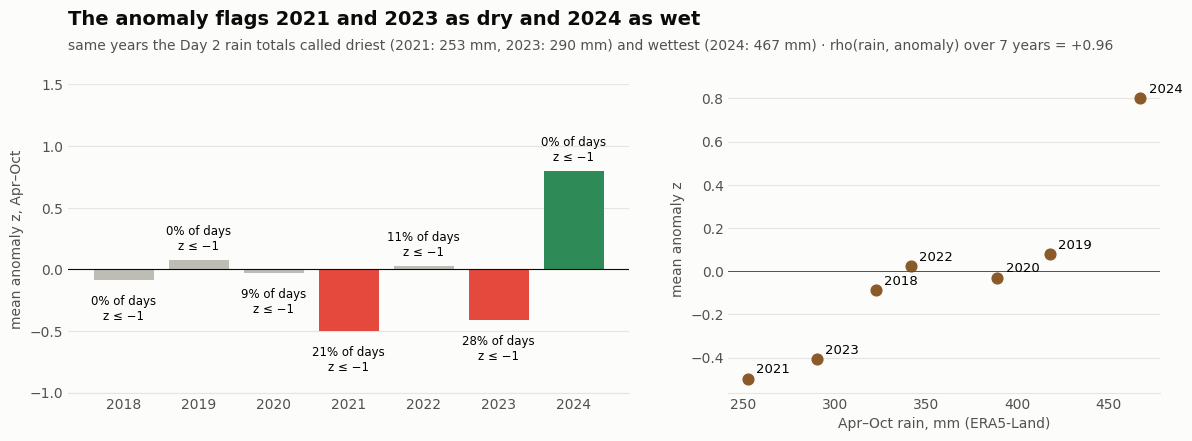

In [7]:
# Figure 3 - which years look dry? (growing season Apr-Oct)
yr = g.groupby("y").agg(mean_z=("z2", "mean"), flagged=("z2", lambda s: (s <= -1).mean() * 100)); yr["rain_AprOct_mm"] = dist[dist.m.between(4, 10)].groupby("y").rain.sum(); yr["events"] = pd.Series([e[0].year for e in EV]).value_counts()
yr["events"] = yr.events.fillna(0).astype(int); print(yr.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]}); fig.subplots_adjust(left=.07, right=.98, top=.8, bottom=.13, wspace=.2); fig.set_facecolor(SURF)
ax[0].bar(yr.index.astype(str), yr.mean_z, color=[FLAG if v < -.3 else (NDVI if v > .3 else "#bdbdb6") for v in yr.mean_z]); style(ax[0]); ax[0].axhline(0, color=INK, lw=.8); ax[0].set_ylabel("mean anomaly z, Apr–Oct", color=INK2)
for i, (v, f_) in enumerate(zip(yr.mean_z, yr.flagged)): ax[0].text(i, v + (.06 if v >= 0 else -.12), f"{f_:.0f}% of days\nz ≤ −1", ha="center", fontsize=8.5, va="bottom" if v >= 0 else "top")
ax[0].set_ylim(-1, 1.5); ax[1].scatter(yr.rain_AprOct_mm, yr.mean_z, s=60, color=SOIL)
for yv, r_ in yr.iterrows(): ax[1].annotate(str(yv), (r_.rain_AprOct_mm, r_.mean_z), xytext=(6, 4), textcoords="offset points", fontsize=9.5)
style(ax[1]); ax[1].set_xlabel("Apr–Oct rain, mm (ERA5-Land)", color=INK2); ax[1].set_ylabel("mean anomaly z", color=INK2); ax[1].axhline(0, color=INK2, lw=.7)
fig.text(.07, .93, "The anomaly flags 2021 and 2023 as dry and 2024 as wet", fontsize=14, fontweight="bold", color=INK)
fig.text(.07, .875, f"same years the Day 2 rain totals called driest (2021: 253 mm, 2023: 290 mm) and wettest (2024: 467 mm) · rho(rain, anomaly) over 7 years = {spearmanr(yr.rain_AprOct_mm, yr.mean_z).statistic:+.2f}", fontsize=10, color=INK2)
fig.savefig(FIG + "target_yearly.png", dpi=170); plt.show()

## 4. Sanity checks: does the anomaly behave like drought?
Three quick tests — it should (a) follow recent rain, (b) fall during the long rain dry spells found on Day 2, and (c) agree with vegetation, in the direction we expect. I also try to break (c): a pooled correlation can come from the season alone. **Caution on (a):** ERA5-Land soil moisture is *computed by a land-surface model from the same rain and temperature*, so agreement with rain is partly built in, not independent evidence.

In [8]:
rain30 = dist.rain.rolling(30).sum(); t14 = dist.t.rolling(14).mean(); gg = dist[dist.m.between(4, 10)]
print(f"(a) anomaly vs rain of the prior 30 days, Apr-Oct: rho = {spearmanr(gg.z2, rain30.loc[gg.index], nan_policy='omit').statistic:+.2f};  vs mean temperature of the prior 14 days: rho = {spearmanr(gg.z2, t14.loc[gg.index], nan_policy='omit').statistic:+.2f}")
sp = pd.read_csv("../reports/dry_spells.csv", parse_dates=["start", "end"]); rows = []
for r in sp.itertuples():
    z = dist.loc[r.start:r.end, "z2"]; zl = dist.loc[r.end:r.end + pd.Timedelta(days=10), "z2"]
    rows.append({"rain dry spell": f"{r.start:%d %b %y} – {r.end:%d %b %y}", "days": r.days, "mean z during": z.mean(), "% days z≤−1": (z <= -1).mean() * 100, "mean z in next 10 d": zl.mean()})
ds_ = pd.DataFrame(rows); print(f"(b) {len(ds_)} rain dry spells: mean anomaly during them {ds_['mean z during'].mean():+.2f}; {(ds_['mean z during'] < 0).sum()} of {len(ds_)} spells have a negative mean anomaly")
ds_.round(2)

(a) anomaly vs rain of the prior 30 days, Apr-Oct: rho = +0.53;  vs mean temperature of the prior 14 days: rho = -0.10
(b) 16 rain dry spells: mean anomaly during them -0.27; 9 of 16 spells have a negative mean anomaly


,rain dry spell,days,mean z during,% days z≤−1,mean z in next 10 d
0,24 Jul 18 – 06 Aug 18,14,-0.23,0.00,0.06
1,31 Aug 18 – 21 Sep 18,22,-0.53,0.00,-0.48
2,04 May 19 – 17 May 19,14,0.23,0.00,-0.43
3,09 Jul 19 – 13 Aug 19,36,-0.65,0.00,-0.52
4,20 May 20 – 04 Jun 20,16,0.44,0.00,0.02
5,12 Jun 20 – 26 Jun 20,15,0.09,0.00,0.24
6,07 Jul 20 – 23 Jul 20,17,0.12,0.00,0.04
7,07 Oct 20 – 22 Oct 20,16,-1.01,50.00,-1.61
8,11 Sep 21 – 01 Oct 21,21,-0.84,14.29,-0.57
9,14 Jul 22 – 27 Jul 22,14,0.43,0.00,0.25


In [9]:
# (c) vegetation: does the year-over-year change in NDVI go with the year-over-year change in the anomaly? (Day 5 asked the same of rain and temperature)
ts = pd.read_csv("../data/processed/sokuluk_ndvi_daily.csv", parse_dates=["date"]).set_index("date"); ts = ts[ts.valid_frac >= .3]
mn = ts.ndvi_mean.groupby([ts.index.year, ts.index.month]).mean().unstack(0); mz = gg.groupby(["y", "m"]).z2.mean().unstack(0)
cmp_ = pd.DataFrame({"NDVI 2023": mn[2023], "NDVI 2024": mn[2024], "z 2023": mz[2023], "z 2024": mz[2024]}).dropna(); cmp_["dNDVI"] = cmp_["NDVI 2024"] - cmp_["NDVI 2023"]; cmp_["dz"] = cmp_["z 2024"] - cmp_["z 2023"]
print(f"district, monthly (Apr-Oct, n = {len(cmp_)}): corr(dNDVI, dz) = {np.corrcoef(cmp_.dNDVI, cmp_.dz)[0, 1]:+.2f}   (Day 5: rain +0.20, temperature -0.23)")
o = d[(d.date >= "2023-04-01") & d.m.between(4, 10)]; cm = o.groupby(["cell_id", "y", "m"]).agg(ndvi=("ndvi", "mean"), z=("z_l2", "mean"), nobs=("ndvi", "count")).reset_index()
a3, b4 = cm[cm.y == 2023].set_index(["cell_id", "m"]), cm[cm.y == 2024].set_index(["cell_id", "m"]); j = b4.join(a3, lsuffix="_24", rsuffix="_23", how="inner"); j = j[(j.nobs_24 >= 2) & (j.nobs_23 >= 2)].dropna(subset=["ndvi_24", "ndvi_23"])
j["dN"], j["dz"] = j.ndvi_24 - j.ndvi_23, j.z_24 - j.z_23; j["month"] = j.index.get_level_values(1)
print(f"cell level, pooled over months ({len(j)} cell-months): rho(dNDVI, dz) = {spearmanr(j.dN, j.dz).statistic:+.2f}   (Day 5: rain +0.14, temperature -0.05)")
# ... but pooled months share a common pattern (spring changes are large in both). Remove it: compare cells WITHIN each month.
bym = j.groupby("month").apply(lambda g: pd.Series({"cells": len(g), "rho(dNDVI, dz)": spearmanr(g.dN, g.dz).statistic})).round(2)
jd = j.assign(dNm=j.dN - j.groupby("month").dN.transform("mean"), dzm=j.dz - j.groupby("month").dz.transform("mean"))
print(f"within each month (across cells, month effect removed): median rho = {bym['rho(dNDVI, dz)'].median():+.2f}, positive in {(bym['rho(dNDVI, dz)'] > 0).sum()} of {len(bym)} months; month-demeaned pooled rho = {spearmanr(jd.dNm, jd.dzm).statistic:+.2f}")
display(bym.T); cmp_.round(2)

district, monthly (Apr-Oct, n = 7): corr(dNDVI, dz) = +0.73   (Day 5: rain +0.20, temperature -0.23)
cell level, pooled over months (174 cell-months): rho(dNDVI, dz) = +0.59   (Day 5: rain +0.14, temperature -0.05)
within each month (across cells, month effect removed): median rho = -0.11, positive in 3 of 7 months; month-demeaned pooled rho = -0.06


month,4,5,6,7,8,9,10
cells,24.00,25.00,25.00,25.00,25.00,25.00,25.00
"rho(dNDVI, dz)",0.34,-0.72,-0.55,0.58,0.57,-0.11,-0.41


,NDVI 2023,NDVI 2024,z 2023,z 2024,dNDVI,dz
4,0.29,0.33,-0.69,0.56,0.04,1.25
5,0.46,0.55,-1.54,1.71,0.09,3.25
6,0.38,0.53,-1.07,0.88,0.15,1.95
7,0.39,0.44,-0.60,0.34,0.05,0.94
8,0.41,0.45,-0.34,0.17,0.04,0.51
9,0.38,0.38,0.89,0.55,0.01,-0.34
10,0.30,0.34,0.51,1.37,0.04,0.86


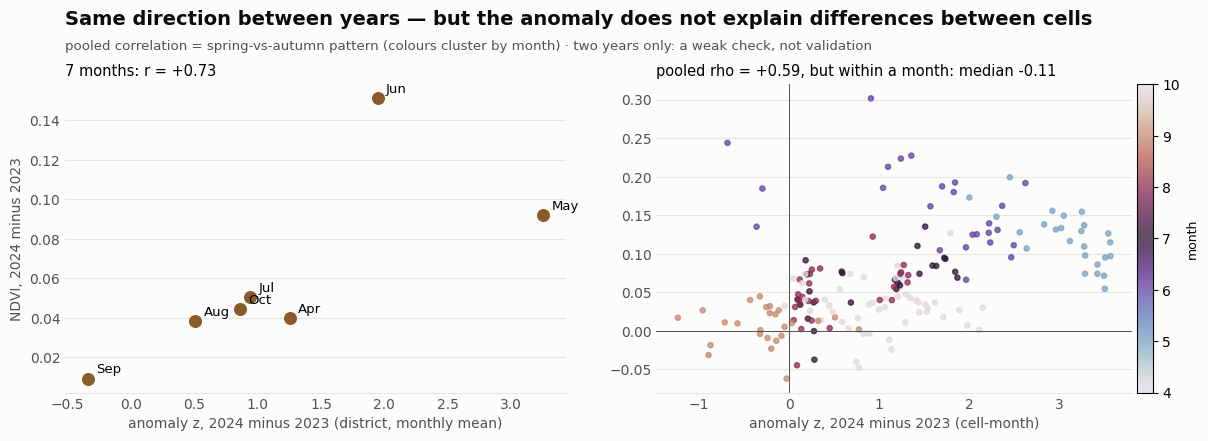

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6)); fig.subplots_adjust(left=.07, right=.98, top=.8, bottom=.13, wspace=.18); fig.set_facecolor(SURF)
ax[0].scatter(cmp_.dz, cmp_.dNDVI, s=70, color=SOIL)
for mth, r_ in cmp_.iterrows(): ax[0].annotate(["", "", "", "", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"][mth], (r_.dz, r_.dNDVI), xytext=(6, 4), textcoords="offset points", fontsize=9.5)
style(ax[0]); ax[0].set_xlabel("anomaly z, 2024 minus 2023 (district, monthly mean)", color=INK2); ax[0].set_ylabel("NDVI, 2024 minus 2023", color=INK2); ax[0].set_title(f"7 months: r = {np.corrcoef(cmp_.dNDVI, cmp_.dz)[0, 1]:+.2f}", loc="left", fontsize=10.5)
sc2 = ax[1].scatter(j.dz, j.dN, s=14, c=j.month, cmap="twilight", alpha=.75); style(ax[1]); ax[1].axhline(0, color=INK2, lw=.7); ax[1].axvline(0, color=INK2, lw=.7); ax[1].set_xlabel("anomaly z, 2024 minus 2023 (cell-month)", color=INK2); fig.colorbar(sc2, ax=ax[1], pad=.01, fraction=.04).set_label("month", fontsize=9)
ax[1].set_title(f"pooled rho = {spearmanr(j.dN, j.dz).statistic:+.2f}, but within a month: median {bym['rho(dNDVI, dz)'].median():+.2f}", loc="left", fontsize=10.5)
fig.text(.07, .93, "Same direction between years — but the anomaly does not explain differences between cells", fontsize=14, fontweight="bold", color=INK)
fig.text(.07, .875, "pooled correlation = spring-vs-autumn pattern (colours cluster by month) · two years only: a weak check, not validation", fontsize=9.6, color=INK2)
fig.savefig(FIG + "target_vs_ndvi.png", dpi=170); plt.show()

## 5. Provisional target and its base rate

**Forecast-ready label:** at the forecast date *t* (growing season, Apr–Oct) the label is **1 if the mean anomaly over the days t+3 … t+7 is ≤ −1**, else 0 — i.e. "will the soil be unusually dry 3–7 days from now?". Below: how common it is, and how well the trivial *persistence* rule ("it is dry today, so it will be dry later") already does. Any model must beat that.

In [11]:
h = []
for c, g_ in d.groupby("cell_id"):
    z = g_.set_index("date").z_l2; fut = pd.concat([z.shift(-k) for k in range(3, 8)], axis=1).mean(axis=1)
    h.append(pd.DataFrame({"cell_id": c, "date": z.index, "z_now": z.values, "z_future": fut.values}))
h = pd.concat(h); h["m"] = h.date.dt.month; h["y"] = h.date.dt.year; h = h[h.m.between(4, 10)].dropna(); h["label"] = (h.z_future <= -1).astype(int)
def auc(score, y): r = rankdata(score); n1 = y.sum(); n0 = len(y) - n1; return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
print(f"{len(h):,} cell-days (Apr-Oct); label = 1 on {h.label.mean()*100:.1f} % of them")
print("share of label = 1 by year (%):", (h.groupby("y").label.mean() * 100).round(0).to_dict())
print(f"persistence baseline (score = -z today): AUC = {auc(-h.z_now.values, h.label.values):.2f}")
print("   ... per year:", {y: round(auc(-g_.z_now.values, g_.label.values), 2) for y, g_ in h.groupby("y") if 0 < g_.label.sum() < len(g_)})

44,940 cell-days (Apr-Oct); label = 1 on 13.2 % of them
share of label = 1 by year (%): {2018: 4.0, 2019: 14.0, 2020: 12.0, 2021: 23.0, 2022: 12.0, 2023: 25.0, 2024: 2.0}
persistence baseline (score = -z today): AUC = 0.93
   ... per year: {2018: np.float64(0.87), 2019: np.float64(0.95), 2020: np.float64(0.93), 2021: np.float64(0.87), 2022: np.float64(0.87), 2023: np.float64(0.94), 2024: np.float64(0.96)}


In [12]:
# how sensitive is the definition? number of growing-season events and flagged days for other thresholds / minimum lengths (district anomaly)
rows = []
for th in (-.5, -1, -1.5):
    for ml in (5, 7, 10):
        n = 0
        for _, gy in g.groupby("y"):
            f = (gy.z2 <= th).values; i = 0
            while i < len(f):
                if f[i]:
                    j_ = i
                    while j_ < len(f) and f[j_]: j_ += 1
                    n += (j_ - i) >= ml; i = j_
                else: i += 1
        rows.append({"threshold z ≤": th, "min days": ml, "events 2018–24": n, "% of days z ≤ threshold": round((g.z2 <= th).mean() * 100, 1)})
pd.DataFrame(rows).pivot(index="threshold z ≤", columns="min days", values="events 2018–24")

min days,5,7,10
threshold z ≤,,,
-1.5,3,2,1
-1.0,7,6,6
-0.5,15,13,11


## 6. Summary

- **Data:** ERA5-Land soil moisture (two layers, m³/m³) is complete for 2018–2024 and shows a strong seasonal cycle, so only a **seasonal anomaly** is a usable signal.
- **Provisional target:** root-zone soil-moisture anomaly z (layer 7–28 cm now; 28–100 cm to be added), with the forecast label "mean z over t+3…t+7 ≤ −1".
- **It behaves like drought at the year level:** it flags 2021 and 2023 as dry and 2024 as wet, follows recent rain (ρ ≈ +0.5), and moves in the same direction as NDVI between 2023 and 2024 (district, 7 months: r ≈ +0.7).
- **But the evidence is thin:** during the 16 rain dry spells the anomaly is negative on average in 9 and strongly so mainly in spring 2023; and the cell-level link to NDVI (pooled ρ ≈ +0.6) **disappears once each month is compared separately** (median within-month ρ ≈ −0.1). So it has not been shown to explain *differences between cells*.
- **Biggest weakness:** the target is produced by a model driven by the same rain and temperature we would use as predictors, so it is **not independent**; it needs validation against truly independent observations (satellite radar soil moisture, evapotranspiration, a multi-year NDVI baseline, station and agronomic records). See `docs/water_stress_target.md`.